<a href="https://colab.research.google.com/github/whitneymbakop/CRM-coursework-1/blob/main/CRM_TASK3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score

In [3]:
features = pd.read_csv('feature_table_with_clusters.csv', index_col=0)
print('Shares:', len(features))
features[['Sector', 'Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM', 'Ward_RF_only']].head()

Shares: 486


,Sector,Ward_RR,KMeans_RR,Ward_RFM,KMeans_RFM,Ward_RF_only
A,Health Care,1,2,1,2,1
AAPL,Information Technology,2,1,2,3,1
ABBV,Health Care,3,4,2,3,2
ABNB,Consumer Discretionary,4,5,2,3,2
ABT,Health Care,5,4,2,2,1


3.2.1 Cluster profiles and sector composition

In [4]:
print('Ward risk/return clusters (k=5)')
print(features.groupby('Ward_RR').agg({'Return_%': 'mean', 'Beta': 'mean',
                                       'Recency': 'median', 'Frequency': 'median',
                                       'Monetary_bn': ['median', 'count']}).round(2))

print('\nWard RFM clusters (k=3)')
print(features.groupby('Ward_RFM').agg({'Recency': 'median', 'Frequency': 'median', 'Monetary_bn': 'median',
                                        'Return_%': 'mean', 'Beta': ['mean', 'count']}).round(2))

Ward risk/return clusters (k=5)
        Return_%  Beta Recency Frequency Monetary_bn      
            mean  mean  median    median      median count
Ward_RR                                                   
1           0.13  0.97    11.0       3.0       12.98   182
2           0.63  1.30    11.0       3.0       24.18    92
3           0.42  0.71    11.0       3.0       17.65    98
4           0.20  1.63    11.0       3.0       28.70    48
5           0.09  0.44    11.0       3.0       17.70    66

Ward RFM clusters (k=3)
         Recency Frequency Monetary_bn Return_%  Beta      
          median    median      median     mean  mean count
Ward_RFM                                                   
1           11.0       3.0       11.15     0.25  0.93   239
2           11.0       3.0       42.01     0.34  1.01   141
3           46.5       2.0       19.49     0.30  1.03   106


In [5]:
print('Sector mix of risk/return clusters (% of each cluster)')
print((pd.crosstab(features['Sector'], features['Ward_RR'], normalize='columns') * 100).round(1))

print('\nSector mix of RFM clusters (% of each cluster)')
print((pd.crosstab(features['Sector'], features['Ward_RFM'], normalize='columns') * 100).round(1))

Sector mix of risk/return clusters (% of each cluster)
Ward_RR                    1     2     3     4     5
Sector                                              
Communication Services   3.8   5.4   5.1   0.0   4.5
Consumer Discretionary   9.3  12.0   9.2  20.8   0.0
Consumer Staples         2.7   0.0   5.1   0.0  33.3
Energy                   0.0   4.3  16.3   0.0   0.0
Financials              14.3  14.1  28.6  10.4   3.0
Health Care             13.7   2.2   8.2   8.3  28.8
Industrials             22.0  22.8  11.2   8.3   3.0
Information Technology  11.0  31.5   2.0  47.9   0.0
Materials                7.7   3.3   3.1   4.2   1.5
Real Estate             12.6   3.3   3.1   0.0   1.5
Utilities                2.7   1.1   8.2   0.0  24.2

Sector mix of RFM clusters (% of each cluster)
Ward_RFM                   1     2     3
Sector                                  
Communication Services   2.9   6.4   3.8
Consumer Discretionary   7.5  12.1  11.3
Consumer Staples         5.9   7.1   7.5
Ene

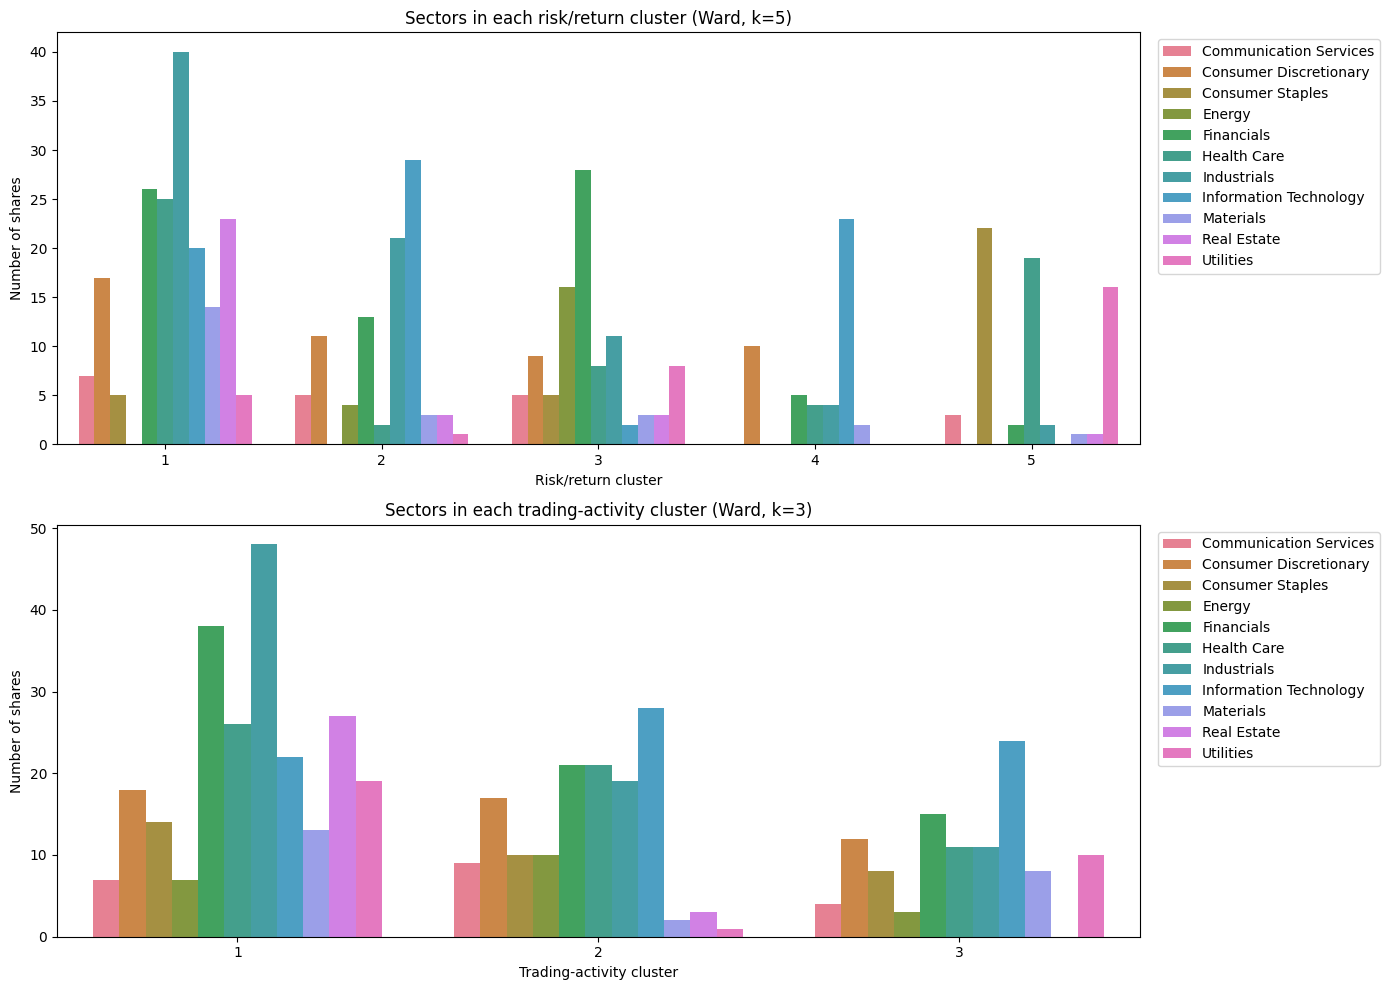

In [8]:
sector_order = sorted(features['Sector'].unique())

plt.figure(figsize=(14, 10))

plt.subplot(2, 1, 1)
sns.countplot(x='Ward_RR', hue='Sector', hue_order=sector_order, data=features)
plt.title('Sectors in each risk/return cluster (Ward, k=5)')
plt.xlabel('Risk/return cluster'); plt.ylabel('Number of shares')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

plt.subplot(2, 1, 2)
sns.countplot(x='Ward_RFM', hue='Sector', hue_order=sector_order, data=features)
plt.title('Sectors in each trading-activity cluster (Ward, k=3)')
plt.xlabel('Trading-activity cluster'); plt.ylabel('Number of shares')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.savefig('sector_composition.png', dpi=150)
plt.show()

In [7]:
print('Rows = risk/return cluster, columns = RFM cluster')
print(pd.crosstab(features['Ward_RR'], features['Ward_RFM']))
print('ARI:', round(adjusted_rand_score(features['Ward_RR'], features['Ward_RFM']), 3))

Rows = risk/return cluster, columns = RFM cluster
Ward_RFM    1   2   3
Ward_RR              
1         114  34  34
2          32  35  25
3          51  32  15
4          15  19  14
5          27  21  18
ARI: 0.048
